# Expectations about inflation, house prices, and the stock market

TECH2 term paper (H25), analyzing US Survey of Consumer Expectations (SCE) data for Norges Bank.

**AI usage statement:** This notebook was developed with the assistance of an AI coding agent (Claude Code), used to help structure the analysis, write and review pandas/matplotlib code, and draft explanations. All code was reviewed and run by the author.

## Part 1 — Reading in the data

We read all monthly SCE survey files from the `data/` folder and merge them into a single `DataFrame`.

In [1]:
from pathlib import Path

import pandas as pd

DATA_DIR = Path('data')

In [2]:
def load_sce_data(data_dir):
    """Read and merge all SCE survey wave files into a single DataFrame.

    Parameters
    ----------
    data_dir : Path
        Directory containing the ``SCE-MMM-YYYY.csv`` wave files.

    Returns
    -------
    DataFrame
        Combined individual-level survey data from all waves.
    """
    # SCE files are semicolon-delimited, unlike the comma-delimited CPI data.
    files = sorted(data_dir.glob('SCE-*.csv'))
    waves = (pd.read_csv(f, sep=';', parse_dates=['date']) for f in files)
    return pd.concat(waves, ignore_index=True)

In [3]:
def report_sample_stats(df, label):
    """Print sample-size statistics for a survey DataFrame.

    Parameters
    ----------
    df : DataFrame
        Individual-level survey data with ``userid``, ``wid``, and ``date``
        columns.
    label : str
        Description of the dataset, used in the printed report.
    """
    n_individuals = df['userid'].nunique()
    n_observations = len(df)
    n_waves = df['wid'].nunique()
    first_date = df['date'].min()
    last_date = df['date'].max()

    print(f'{label}')
    print(f'  Unique individuals: {n_individuals}')
    print(f'  Observations (rows): {n_observations}')
    print(f'  Unique survey waves: {n_waves}')
    print(f'  First date observed: {first_date.date()}')
    print(f'  Last date observed: {last_date.date()}')

In [4]:
sce = load_sce_data(DATA_DIR)

In [5]:
report_sample_stats(sce, 'Raw sample')

Raw sample
  Unique individuals: 23369
  Observations (rows): 176101
  Unique survey waves: 139
  First date observed: 2013-06-01
  Last date observed: 2024-12-31


## Part 2 — Data pre-processing


### Fill missing numeracy responses

The numeracy questions are only asked in a respondent's first wave, so we carry those answers forward to later waves for the same individual.


In [6]:
DEMOGRAPHIC_COLS = ['female', 'age', 'educ']
EXPECTATION_COLS = ['inflation', 'house_price_change', 'prob_stocks_up']
NUMERACY_COLS = [
    'num_lit_q1_correct',
    'num_lit_q2_correct',
    'num_lit_q3_correct',
    'num_lit_q5_correct',
    'num_lit_q6_correct',
    'num_lit_q8_correct',
    'num_lit_q9_correct',
]

In [7]:
def fill_numeracy(df, cols):
    """Fill missing numeracy indicators using each individual's first observation.

    The numeracy questions are only asked the first time a respondent enters
    the survey, so later waves have missing values in ``cols``. This fills
    them in using the value from each individual's earliest survey date.

    Parameters
    ----------
    df : DataFrame
        Individual-level survey data, with one row per respondent per wave.
    cols : list of str
        Numeracy indicator columns to fill.

    Returns
    -------
    DataFrame
        Copy of ``df`` with ``cols`` filled within each ``userid`` group.
    """
    df = df.sort_values(['userid', 'date'])
    df[cols] = df.groupby('userid')[cols].transform('first')
    return df

In [8]:
sce = fill_numeracy(sce, NUMERACY_COLS)

### Drop missing observations

We drop rows missing demographic information, expectations responses, or numeracy responses (after the fill above), reporting the number of observations dropped at each step.


In [9]:
def drop_missing(df, cols, label):
    """Drop rows with missing values in ``cols`` and report how many were dropped.

    Parameters
    ----------
    df : DataFrame
        Data to filter.
    cols : list of str
        Columns checked for missing values.
    label : str
        Description of this step, used in the printed report.

    Returns
    -------
    DataFrame
        Subset of ``df`` with no missing values in ``cols``.
    """
    before = len(df)
    df = df.dropna(subset=cols)
    print(f'{label}: dropped {before - len(df)} observations ({len(df)} remaining)')
    return df

In [10]:
sce = drop_missing(sce, DEMOGRAPHIC_COLS, 'Missing demographics')
sce = drop_missing(sce, EXPECTATION_COLS, 'Missing expectations')
sce = drop_missing(sce, NUMERACY_COLS, 'Missing numeracy (after fill)')

Missing demographics: dropped 868 observations (175233 remaining)
Missing expectations: dropped 1683 observations (173550 remaining)
Missing numeracy (after fill): dropped 35974 observations (137576 remaining)


### Drop outliers

For each expectations variable, we drop observations below the 0.1th percentile and above the 99.9th percentile, reporting the number dropped at each bound.


In [11]:
def drop_outliers(df, col):
    """Drop observations with extreme values in ``col`` based on percentiles.

    Observations below the 0.1th percentile or above the 99.9th percentile
    are dropped, with each bound reported separately.

    Parameters
    ----------
    df : DataFrame
        Data to filter.
    col : str
        Expectations column to trim.

    Returns
    -------
    DataFrame
        Subset of ``df`` with outliers in ``col`` removed.
    """
    lower, upper = df[col].quantile([0.001, 0.999])

    before = len(df)
    df = df[df[col] >= lower]
    print(f'{col}: dropped {before - len(df)} observations below {lower:.2f}')

    before = len(df)
    df = df[df[col] <= upper]
    print(f'{col}: dropped {before - len(df)} observations above {upper:.2f}')

    return df

In [12]:
for col in EXPECTATION_COLS:
    sce = drop_outliers(sce, col)

inflation: dropped 92 observations below -75.00
inflation: dropped 27 observations above 100.00
house_price_change: dropped 133 observations below -50.00
house_price_change: dropped 46 observations above 100.00
prob_stocks_up: dropped 0 observations below 0.00
prob_stocks_up: dropped 0 observations above 100.00


### Derived variables: college and numerical literacy

`college` flags respondents with a bachelor's degree or higher. `num_lit_high` flags respondents whose total numeracy score is above the sample median.


In [13]:
sce['college'] = (sce['educ'] == 4).astype(int)

In [14]:
sce['num_lit_total'] = sce[NUMERACY_COLS].sum(axis=1)

# One row per individual, since numeracy indicators are now constant within userid.
numeracy_dist = (
    sce.drop_duplicates('userid')['num_lit_total']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)
print('Share of individuals (%) by number of correct numeracy responses:')
print(numeracy_dist.round(1).to_string())

Share of individuals (%) by number of correct numeracy responses:
num_lit_total
0.0     0.1
1.0     0.7
2.0     2.4
3.0     5.7
4.0    10.5
5.0    16.9
6.0    27.4
7.0    36.2


In [15]:
median_num_lit = sce.drop_duplicates('userid')['num_lit_total'].median()
sce['num_lit_high'] = (sce['num_lit_total'] > median_num_lit).astype(int)

### Final sample size


In [16]:
report_sample_stats(sce, 'Cleaned sample')

Cleaned sample
  Unique individuals: 17701
  Observations (rows): 137278
  Unique survey waves: 117
  First date observed: 2015-04-02
  Last date observed: 2024-12-31


## Part 3 — Average expectations by group

For each grouping variable (gender, education, numeracy), we compare average expectations for inflation, house prices, and the stock market across the two groups.


In [17]:
import matplotlib.pyplot as plt

EXPECTATION_LABELS = {
    'inflation': 'Expected inflation (%)',
    'house_price_change': 'Expected house price change (%)',
    'prob_stocks_up': 'Probability stocks rise (%)',
}

In [18]:
def plot_group_means(df, group_col, group_labels, title):
    """Plot average expectations for two groups side by side.

    Creates a figure with one panel per expectations variable in
    ``EXPECTATION_COLS``, each showing a bar chart comparing the group
    means.

    Parameters
    ----------
    df : DataFrame
        Cleaned individual-level survey data.
    group_col : str
        Binary (0/1) column defining the two groups.
    group_labels : dict
        Mapping from the two values of ``group_col`` to display labels,
        e.g. ``{0: 'Male', 1: 'Female'}``.
    title : str
        Overall figure title.

    Returns
    -------
    Figure
        The created matplotlib figure.
    """
    means = df.groupby(group_col)[EXPECTATION_COLS].mean()

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    for ax, col in zip(axes, EXPECTATION_COLS, strict=True):
        labels = [group_labels[g] for g in means.index]
        ax.bar(labels, means[col], color=['#4C72B0', '#DD8452'])
        ax.set_title(EXPECTATION_LABELS[col])
        ax.set_ylabel(EXPECTATION_LABELS[col])

    fig.suptitle(title)
    fig.tight_layout()
    return fig

### Males vs. females


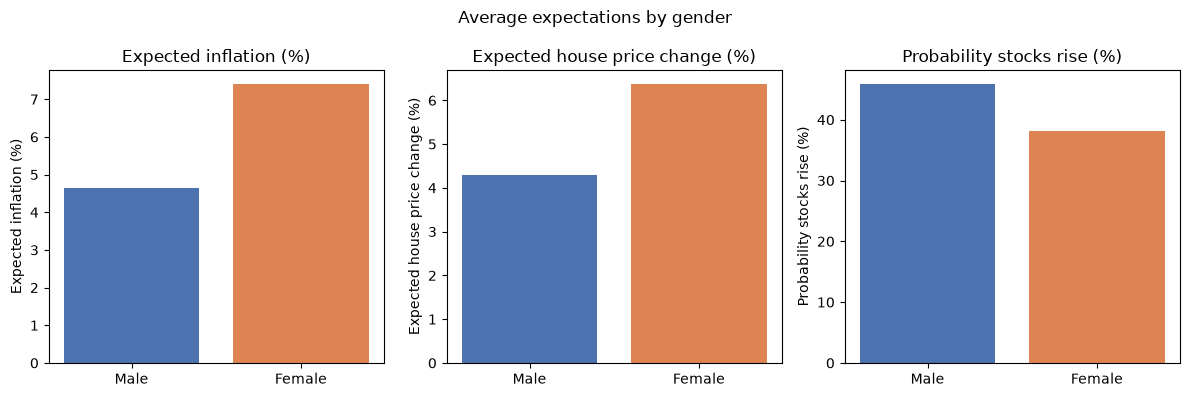

In [19]:
_ = plot_group_means(
    sce, 'female', {0: 'Male', 1: 'Female'}, 'Average expectations by gender'
)

### Non-college vs. college


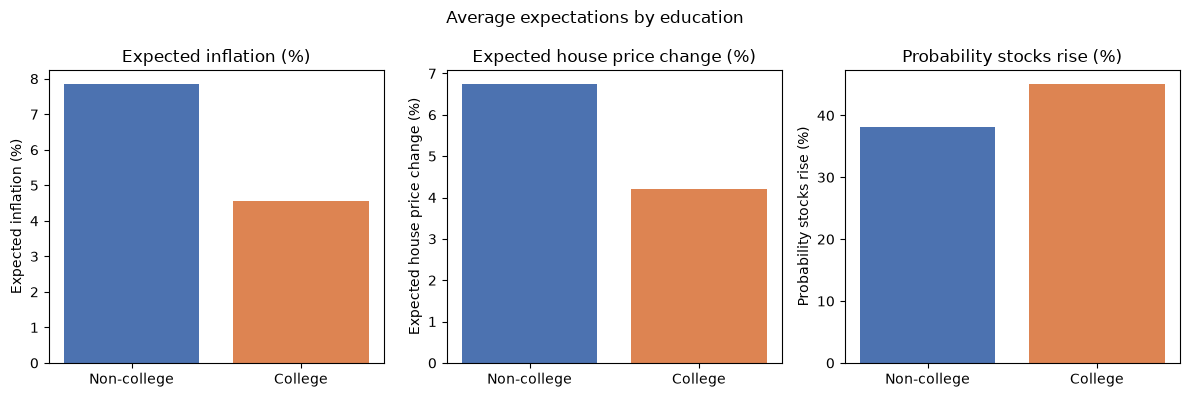

In [20]:
_ = plot_group_means(
    sce,
    'college',
    {0: 'Non-college', 1: 'College'},
    'Average expectations by education',
)

### Low vs. high numeracy


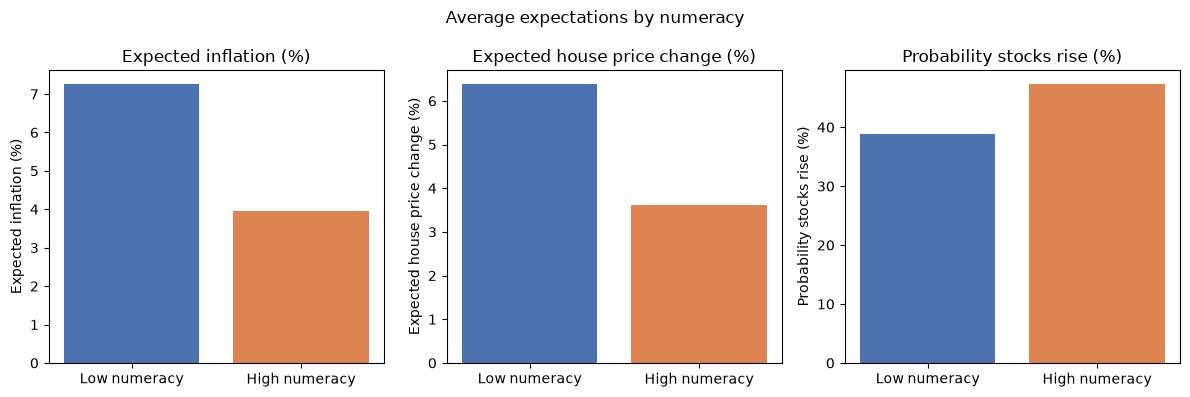

In [21]:
_ = plot_group_means(
    sce,
    'num_lit_high',
    {0: 'Low numeracy', 1: 'High numeracy'},
    'Average expectations by numeracy',
)

## Part 4 — Expectation dynamics by group

We track monthly average expectations for 2015–2024 across the same three grouping variables, and overlay notable geopolitical events to see how expectations reacted.


In [22]:
EVENTS = [
    ('2016-11-08', 'Trump elected (1st)'),
    ('2020-02-01', 'COVID-19 goes global'),
    ('2020-11-03', 'Biden elected'),
    ('2022-02-24', 'Russia invades Ukraine'),
    ('2023-10-03', 'Nobel Prize: Jon Fosse'),
    ('2024-11-05', 'Trump elected (2nd)'),
]

In [23]:
def monthly_group_means(df, group_col):
    """Compute monthly average expectations for each group.

    Parameters
    ----------
    df : DataFrame
        Cleaned individual-level survey data.
    group_col : str
        Binary (0/1) column defining the two groups.

    Returns
    -------
    DataFrame
        Monthly means of each expectations variable, with columns indexed
        by (expectations variable, group value).
    """
    monthly = df.groupby([pd.Grouper(key='date', freq='MS'), group_col])[
        EXPECTATION_COLS
    ].mean()
    return monthly.unstack(group_col)

In [24]:
def plot_group_timeseries(df, group_col, group_labels, title):
    """Plot monthly expectation time series for two groups with event markers.

    Creates a figure with three vertically stacked panels (one per
    expectations variable), each showing the monthly group means over
    time, with vertical lines marking the events in ``EVENTS``.

    Parameters
    ----------
    df : DataFrame
        Cleaned individual-level survey data.
    group_col : str
        Binary (0/1) column defining the two groups.
    group_labels : dict
        Mapping from the two values of ``group_col`` to display labels.
    title : str
        Overall figure title.

    Returns
    -------
    Figure
        The created matplotlib figure.
    """
    monthly = monthly_group_means(df, group_col)

    fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
    for ax, col in zip(axes, EXPECTATION_COLS, strict=True):
        for group, label in group_labels.items():
            ax.plot(monthly.index, monthly[col][group], label=label)
        for event_date, _ in EVENTS:
            ax.axvline(
                pd.Timestamp(event_date), color='gray', linestyle='--', linewidth=0.8
            )
        ax.set_ylabel(EXPECTATION_LABELS[col])
        ax.legend(loc='upper left')

    # Annotate events once, on the top panel only, to avoid clutter.
    for event_date, event_label in EVENTS:
        axes[0].annotate(
            event_label,
            xy=(pd.Timestamp(event_date), axes[0].get_ylim()[1]),
            rotation=90,
            fontsize=7,
            ha='right',
            va='top',
        )

    axes[-1].set_xlabel('Date')
    fig.suptitle(title)
    fig.tight_layout()
    return fig

### Males vs. females


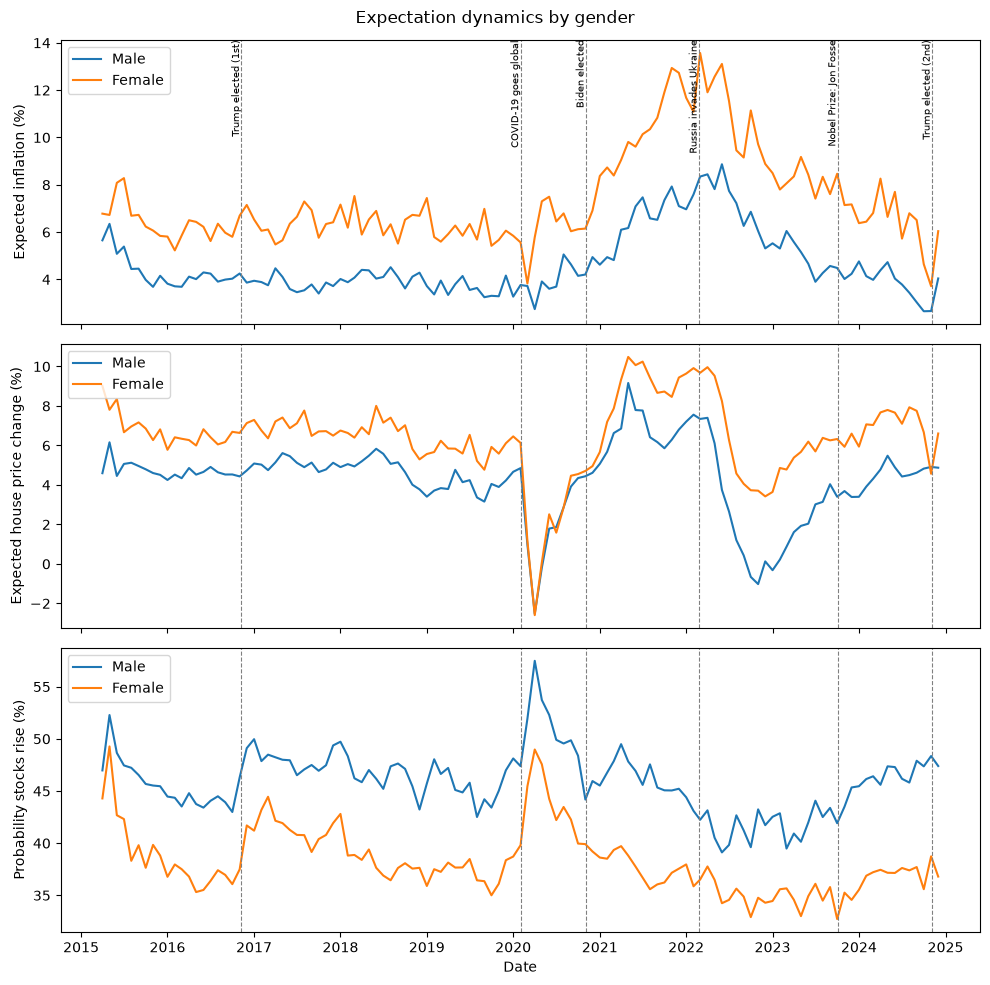

In [25]:
_ = plot_group_timeseries(
    sce, 'female', {0: 'Male', 1: 'Female'}, 'Expectation dynamics by gender'
)

### Non-college vs. college


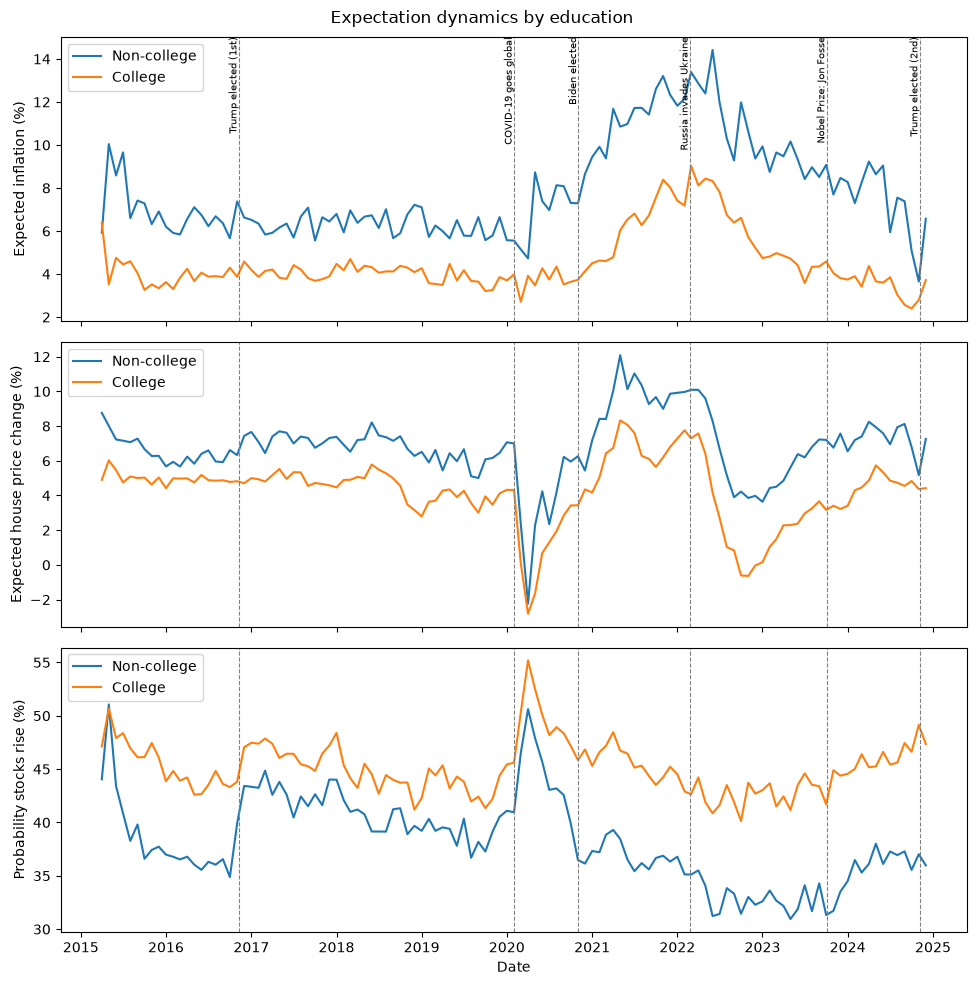

In [26]:
_ = plot_group_timeseries(
    sce,
    'college',
    {0: 'Non-college', 1: 'College'},
    'Expectation dynamics by education',
)

### Low vs. high numeracy


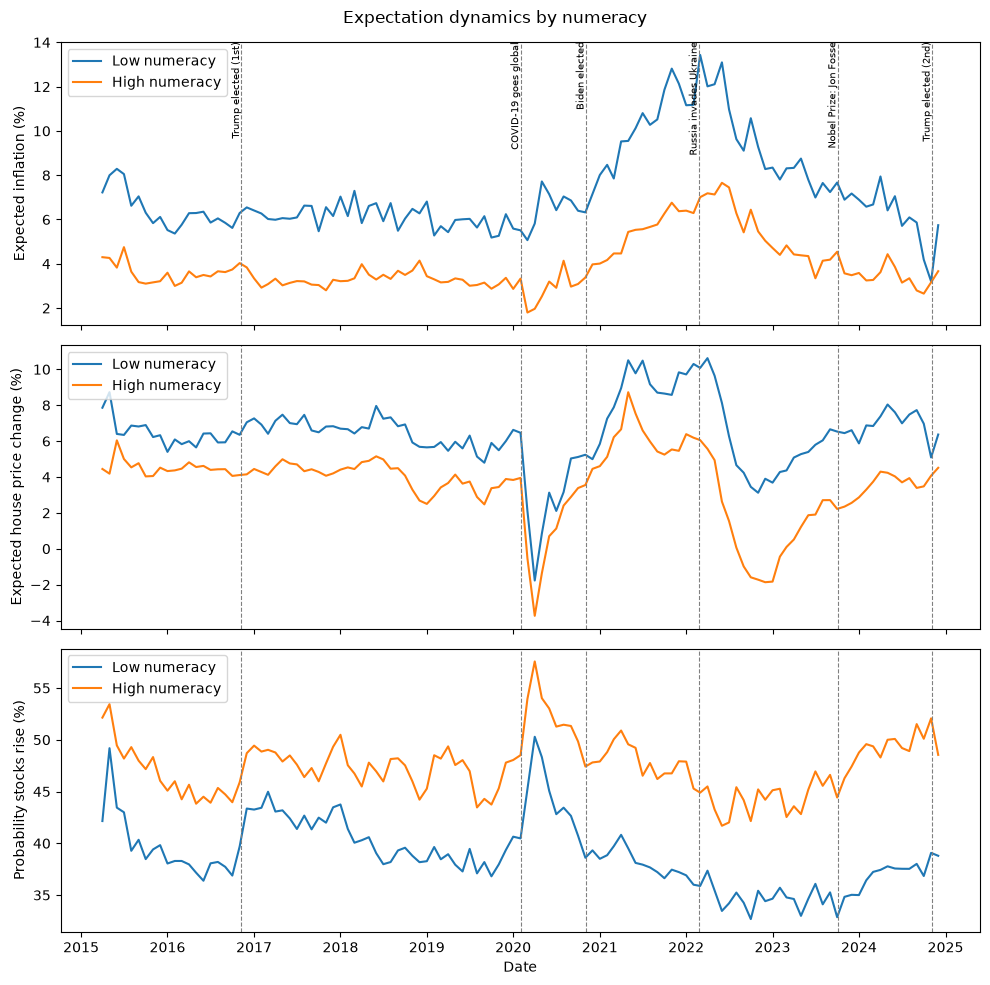

In [27]:
_ = plot_group_timeseries(
    sce,
    'num_lit_high',
    {0: 'Low numeracy', 1: 'High numeracy'},
    'Expectation dynamics by numeracy',
)

### Discussion

**Which events moved expectations?** COVID-19 (February 2020) has by far the
largest and sharpest effect: expected house price changes crash to roughly
zero or negative within a month before rebounding, the probability of a
stock-market increase spikes as markets initially sold off and respondents
reportedly expected a rebound, and inflation expectations begin a sustained
climb that continues through 2021–2022, overlapping with Russia's invasion of
Ukraine (February 2022), which coincides with the peak of expected inflation
(around 13%) before it gradually recedes. The two US presidential elections
(2016, 2024) line up with smaller, short-lived upticks in the probability of
a stock-market increase, consistent with anticipated pro-business policy, but
have little visible effect on inflation or house-price expectations. The
Nobel Prize in Literature (October 2023), included as a placebo event with no
plausible economic content, shows no corresponding movement in any series —
reassuring us that the other co-movements are not simply noise.

**Differences across groups.** Non-college, low-numeracy, and (to a smaller
extent) female respondents consistently report higher and more volatile
inflation and house-price expectations than college-educated, high-numeracy,
and male respondents, with the gap widening sharply during the 2021–2022
inflation run-up. The same lower-numeracy/non-college/female groups are
persistently less optimistic about the stock market (lower probability of a
rise) throughout the sample. All groups react to COVID and the inflation
surge in the same direction and at the same time, so the differences are in
level and amplitude rather than timing — groups with less formal education or
numerical literacy appear to form more extreme expectations in response to
the same events.

## Part 5 — Correlations with past & future realizations

We compare average expected inflation by gender (from Part 4) to realized inflation computed from monthly CPI data, both looking forward and looking backward 12 months. This part uses monthly data only; individual-level SCE data is not needed.


In [28]:
CPI_PATH = DATA_DIR / 'CPI.csv'

In [29]:
def load_cpi(path):
    """Load monthly CPI level data.

    Parameters
    ----------
    path : Path
        Path to the CPI CSV file (comma-delimited, with ``DATE`` and
        ``CPI`` columns).

    Returns
    -------
    DataFrame
        CPI data with columns ``date`` and ``CPI``.
    """
    cpi = pd.read_csv(path, parse_dates=['DATE'])
    return cpi.rename(columns={'DATE': 'date'})

In [30]:
def compute_realized_inflation(cpi, direction):
    """Compute realized annual inflation from monthly CPI levels.

    Parameters
    ----------
    cpi : DataFrame
        Monthly CPI data with columns ``date`` and ``CPI``.
    direction : {'forward', 'backward'}
        Whether to compute inflation over the following or preceding
        12 months.

    Returns
    -------
    DataFrame
        ``cpi`` with an added ``inflation`` column.
    """
    cpi = cpi.sort_values('date').copy()
    if direction == 'forward':
        # Inflation_t = (CPI_{t+12} - CPI_t) / CPI_t * 100
        cpi['inflation'] = (cpi['CPI'].shift(-12) - cpi['CPI']) / cpi['CPI'] * 100
    elif direction == 'backward':
        # Inflation_t = (CPI_t - CPI_{t-12}) / CPI_{t-12} * 100
        cpi['inflation'] = (
            (cpi['CPI'] - cpi['CPI'].shift(12)) / cpi['CPI'].shift(12) * 100
        )
    else:
        raise ValueError(f'Unknown direction: {direction}')
    return cpi

In [31]:
def plot_expectation_vs_realized(exp_inflation, realized, group_labels, title):
    """Scatter expected vs. realized inflation for two groups.

    Creates a figure with one panel per group, each showing realized
    inflation (CPI-based) against average expected inflation (SCE-based),
    annotated with the correlation coefficient.

    Parameters
    ----------
    exp_inflation : DataFrame
        Monthly average expected inflation by group (columns = group
        values), indexed by month.
    realized : Series
        Realized inflation, indexed by month, aligned with
        ``exp_inflation``.
    group_labels : dict
        Mapping from group values to display labels.
    title : str
        Overall figure title.

    Returns
    -------
    Figure
        The created matplotlib figure.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    for ax, (group, label) in zip(axes, group_labels.items(), strict=True):
        data = pd.concat(
            [exp_inflation[group], realized], axis=1, join='inner'
        ).dropna()
        x, y = data.iloc[:, 0], data.iloc[:, 1]
        corr = x.corr(y)

        ax.scatter(x, y, alpha=0.6, s=15)
        ax.set_title(label)
        ax.set_xlabel('Average expected inflation (%)')
        ax.annotate(f'corr = {corr:.2f}', xy=(0.05, 0.92), xycoords='axes fraction')

    axes[0].set_ylabel('Realized inflation (%)')
    fig.suptitle(title)
    fig.tight_layout()
    return fig

In [32]:
cpi = load_cpi(CPI_PATH)
exp_inflation = monthly_group_means(sce, 'female')['inflation']

### Realized future inflation


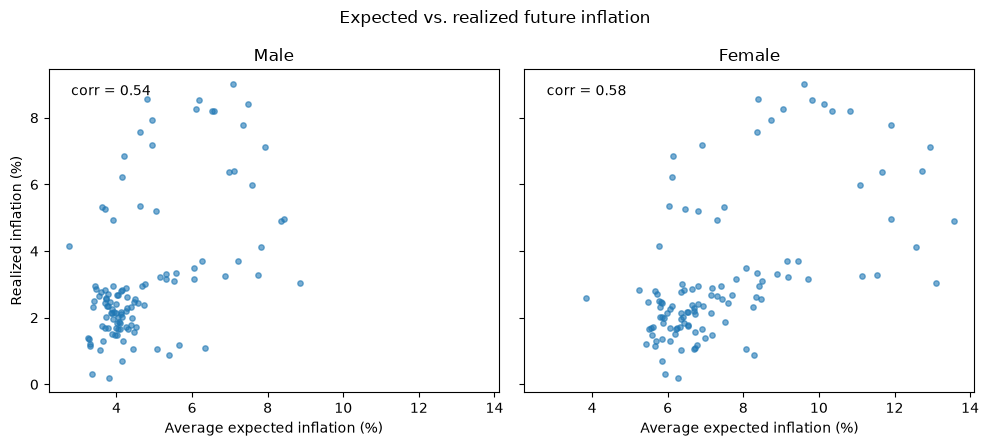

In [33]:
cpi_forward = compute_realized_inflation(cpi, 'forward').set_index('date')['inflation']
_ = plot_expectation_vs_realized(
    exp_inflation,
    cpi_forward,
    {0: 'Male', 1: 'Female'},
    'Expected vs. realized future inflation',
)

### Realized past inflation


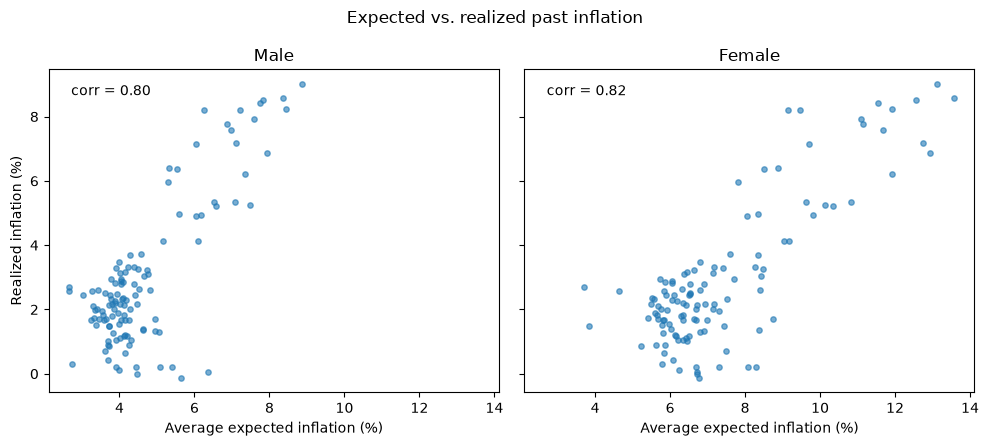

In [34]:
cpi_backward = compute_realized_inflation(cpi, 'backward').set_index('date')[
    'inflation'
]
_ = plot_expectation_vs_realized(
    exp_inflation,
    cpi_backward,
    {0: 'Male', 1: 'Female'},
    'Expected vs. realized past inflation',
)

### Discussion

Expected inflation correlates more strongly with realized *past* inflation
(0.80 for men, 0.82 for women) than with realized *future* inflation (0.54
for men, 0.58 for women). This is more consistent with respondents
extrapolating from recently experienced inflation than with expectations
that accurately anticipate where inflation is headed 12 months out — if
beliefs were forward-looking and well-informed, the forward correlation
should be at least as strong as the backward one, not weaker. Both genders
show essentially the same pattern and magnitude of correlations, with women
very slightly more correlated with realized inflation (both past and
future) than men; the gender gap in the strength of the relationship is
small compared to the backward-vs-forward gap, so extrapolative behavior
looks like a broadly shared feature of how people form inflation
expectations, rather than something that differs much by gender.